In [1]:

!pip -q install soundfile scikit-learn matplotlib tqdm


# Import everything

In [2]:

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from pathlib import Path
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import Audio, display

import random
import zipfile
import urllib.request

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Using device:", device)


PyTorch version: 2.11.0+cu130
Using device: cuda


# Download our dataset

In [3]:

url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "data/mini_speech_commands.zip"
)

zip_path = Path("mini_speech_commands.zip")
data_dir = Path("data")
dataset_dir = data_dir / "mini_speech_commands"

data_dir.mkdir(exist_ok=True)

if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

if not dataset_dir.exists():
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(data_dir)

classes = sorted([
    p.name for p in dataset_dir.iterdir()
    if p.is_dir()
])

print("Classes:", classes)

for word in classes:
    count = len(list((dataset_dir / word).glob("*.wav")))
    print(f"{word}: {count} recordings")


Classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
down: 1000 recordings
go: 1000 recordings
left: 1000 recordings
no: 1000 recordings
right: 1000 recordings
stop: 1000 recordings
up: 1000 recordings
yes: 1000 recordings


# Listen to an audio recording detecting for yes

In [4]:

file_path = sorted((dataset_dir / "yes").glob("*.wav"))[0]

waveform, sample_rate = sf.read(file_path)

print("Sample rate:", sample_rate)
print("Number of samples:", len(waveform))
print("Duration:", len(waveform) / sample_rate, "seconds")

display(Audio(waveform, rate=sample_rate))


Sample rate: 16000
Number of samples: 16000
Duration: 1.0 seconds


# Visualize the waveform

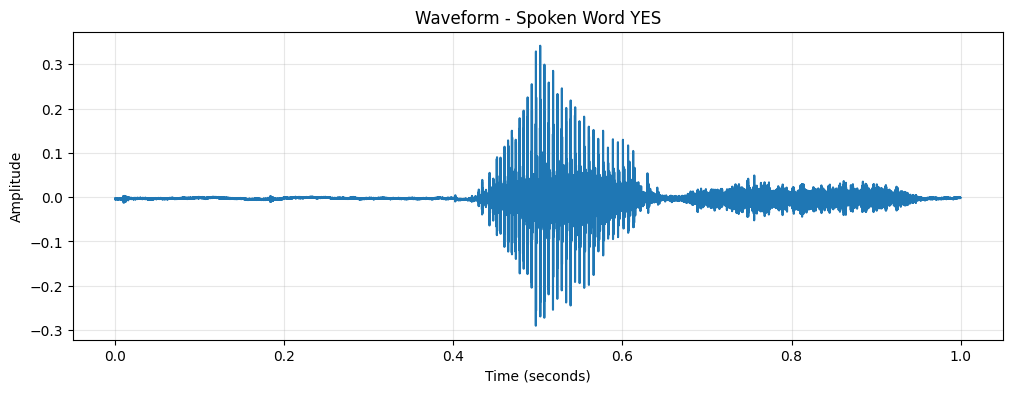

In [5]:

time = np.arange(len(waveform)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(time, waveform)

plt.title("Waveform - Spoken Word YES")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)

plt.show()


# Convert audio into features

In [6]:

SAMPLE_RATE = 16000
NUM_SAMPLES = 16000

def load_audio(path):
    audio, sr = sf.read(str(path), dtype="float32")

    # Convert stereo into mono if necessary.
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    if sr != SAMPLE_RATE:
        raise ValueError(
            f"Expected {SAMPLE_RATE} Hz, got {sr} Hz"
        )

    # Make every example exactly one second.
    if len(audio) < NUM_SAMPLES:
        audio = np.pad(
            audio, (0, NUM_SAMPLES - len(audio))
        )

    audio = audio[:NUM_SAMPLES]

    return torch.tensor(audio, dtype=torch.float32)


def audio_to_spectrogram(audio):
    # Short-time Fourier transform
    window = torch.hann_window(400, device=audio.device)

    stft = torch.stft(
        audio,
        n_fft=400,
        hop_length=160,
        win_length=400,
        window=window,
        return_complex=True
    )

    magnitude = stft.abs()

    # Log scale makes weak and strong components
    # easier for the model to work with.
    log_spec = torch.log1p(magnitude)

    return log_spec


n_fft=400: Analyzes frequency content using a 400-sample window, equivalent to 25 milliseconds.



hop_length=160: Moves the analysis window by 10 milliseconds each time.



torch.log1p: Compresses large differences in magnitude.
#Visualize our spectrogram

Waveform shape: torch.Size([16000])
Spectrogram shape: torch.Size([201, 101])


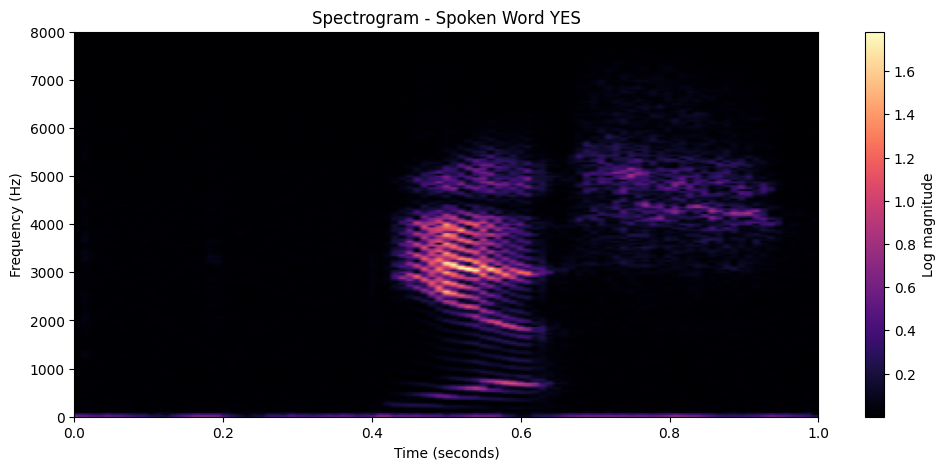

In [7]:

audio = load_audio(file_path)

spec = audio_to_spectrogram(audio)

print("Waveform shape:", audio.shape)
print("Spectrogram shape:", spec.shape)

plt.figure(figsize=(12, 5))

plt.imshow(
    spec.numpy(),
    aspect="auto",
    origin="lower",
    extent=[0, 1, 0, 8000],
    cmap="magma"
)

plt.title("Spectrogram - Spoken Word YES")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Log magnitude")

plt.show()


We converted 16,000 audio samples into a matrix with approximately 201 frequency bins and 101 time frames.

That matrix becomes the input to our CNN.
#Prepare the data for training

In [8]:

class_to_id = {
    name: index
    for index, name in enumerate(classes)
}

files = []
labels = []

for word in classes:
    for path in sorted((dataset_dir / word).glob("*.wav")):
        files.append(path)
        labels.append(class_to_id[word])

# 70% train, 15% validation, 15% test
train_files, temp_files, train_labels, temp_labels = (
    train_test_split(
        files,
        labels,
        test_size=0.30,
        random_state=42,
        stratify=labels
    )
)

val_files, test_files, val_labels, test_labels = (
    train_test_split(
        temp_files,
        temp_labels,
        test_size=0.50,
        random_state=42,
        stratify=temp_labels
    )
)

print("Training:", len(train_files))
print("Validation:", len(val_files))
print("Testing:", len(test_files))
print("Labels:", class_to_id)


Training: 5600
Validation: 1200
Testing: 1200
Labels: {'down': 0, 'go': 1, 'left': 2, 'no': 3, 'right': 4, 'stop': 5, 'up': 6, 'yes': 7}


In [9]:

class SpeechDataset(Dataset):
    def __init__(self, paths, labels):
        self.paths = paths
        self.labels = labels

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        label = self.labels[index]

        # Load audio
        audio = load_audio(path)

        # Convert to spectrogram
        spec = audio_to_spectrogram(audio)

        # Add channel dimension for CNN
        spec = spec.unsqueeze(0)

        return spec, torch.tensor(label, dtype=torch.long)


train_dataset = SpeechDataset(train_files, train_labels)
val_dataset = SpeechDataset(val_files, val_labels)
test_dataset = SpeechDataset(test_files, test_labels)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

batch_x, batch_y = next(iter(train_loader))

print("Input batch:", batch_x.shape)
print("Labels:", batch_y.shape)


Input batch: torch.Size([32, 1, 201, 101])
Labels: torch.Size([32])


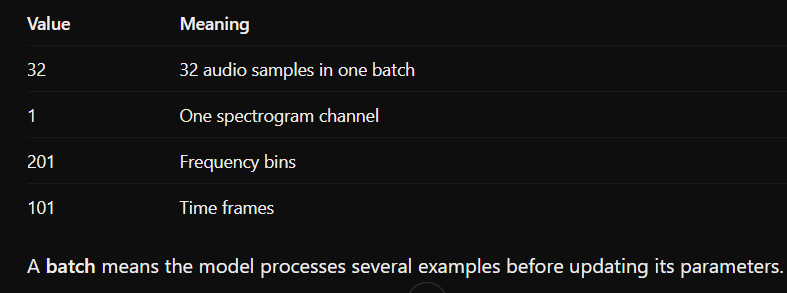

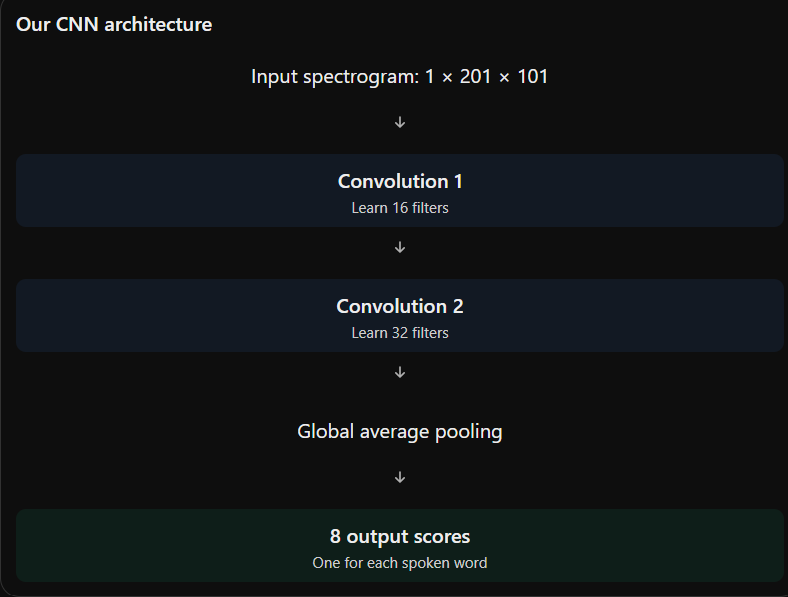

In [10]:

class WakeWordCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.features(x)

        x = torch.flatten(x, start_dim=1)

        x = self.classifier(x)

        return x


model = WakeWordCNN(
    num_classes=len(classes)
).to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Trainable parameters:", total_params)


WakeWordCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=8, bias=True)
)
Trainable parameters: 24040


Conv2d learns filters that detect local patterns, such as changes in frequency over short periods.

ReLU introduces nonlinearity, allowing the network to learn more complex patterns.

MaxPool2d reduces the dimensions of feature maps and helps build tolerance to small shifts in the input.

BatchNorm2d helps stabilize training.

AdaptiveAvgPool2d summarizes the final feature maps into 64 values.

Linear converts those values into eight output scores.

Notice that we didn't download a pretrained model. PyTorch randomly initializes these neural-network parameters, and we will train them using the dataset.

In [11]:

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", loss_fn)
print("Optimizer:", optimizer)


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [12]:

def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0
    correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        with torch.set_grad_enabled(is_training):
            outputs = model(x)
            loss = loss_fn(outputs, y)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total


EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(
        model, train_loader, optimizer
    )

    val_loss, val_acc = run_epoch(
        model, val_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_cnn.pth")

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )


Epoch 1/10 | Train Loss: 1.9497 | Train Acc: 27.00% | Val Loss: 1.8779 | Val Acc: 30.00%
Epoch 2/10 | Train Loss: 1.7643 | Train Acc: 36.93% | Val Loss: 2.1490 | Val Acc: 18.33%
Epoch 3/10 | Train Loss: 1.6463 | Train Acc: 41.66% | Val Loss: 1.7893 | Val Acc: 29.75%
Epoch 4/10 | Train Loss: 1.5323 | Train Acc: 48.32% | Val Loss: 1.5965 | Val Acc: 37.50%
Epoch 5/10 | Train Loss: 1.4261 | Train Acc: 52.62% | Val Loss: 2.5604 | Val Acc: 15.25%
Epoch 6/10 | Train Loss: 1.3154 | Train Acc: 58.00% | Val Loss: 1.4358 | Val Acc: 43.00%
Epoch 7/10 | Train Loss: 1.2189 | Train Acc: 61.50% | Val Loss: 1.9835 | Val Acc: 34.08%
Epoch 8/10 | Train Loss: 1.1663 | Train Acc: 62.96% | Val Loss: 2.9060 | Val Acc: 18.50%
Epoch 9/10 | Train Loss: 1.0957 | Train Acc: 65.18% | Val Loss: 1.2424 | Val Acc: 51.58%
Epoch 10/10 | Train Loss: 1.0342 | Train Acc: 67.20% | Val Loss: 1.3376 | Val Acc: 47.42%


# Plot the training results

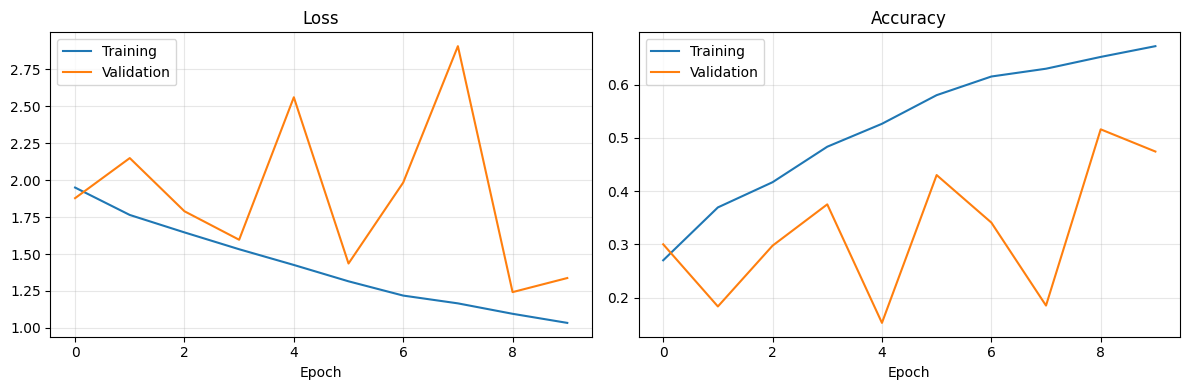

In [13]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Training")
plt.plot(history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Training")
plt.plot(history["val_acc"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Evaluate on test recordings

In [14]:

model.load_state_dict(
    torch.load(
        "best_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

test_loss, test_accuracy = run_epoch(
    model,
    test_loader
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")


Test Loss: 1.2388
Test Accuracy: 51.50%


# Make a prediction

In [15]:

model.eval()

sample_path = test_files[0]
actual_label = classes[test_labels[0]]

audio = load_audio(sample_path)
spec = audio_to_spectrogram(audio)

# Shape: [batch, channel, frequency, time]
input_tensor = spec.unsqueeze(0).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)

predicted_id = probabilities.argmax(dim=1).item()
confidence = probabilities[0, predicted_id].item()

print("Actual word:", actual_label)
print("Predicted word:", classes[predicted_id])
print(f"Confidence: {confidence:.2%}")

display(Audio(audio.numpy(), rate=SAMPLE_RATE))


Actual word: stop
Predicted word: up
Confidence: 42.60%
